**MODULE 2 — DATA PREPARATION**

In [2]:
# CRISP-DM Phase 2

# Datasets processed:
#   - CholecTrack20    → cholec/ (folder)     ~4000 frames
#   - ROBUST-MIPS      → rob.zip              ~2500 frames
#   - Badilla-Solórzano→ badilla.zip          ~1500 frames

# Universal Taxonomy (7 classes):
#   0:Grasper  1:Hook  2:Scissors  3:Clipper
#   4:Irrigator  5:Bipolar  6:Specimen Bag

In [1]:
# IMPORTING LIBRARIES

import os
import cv2
import json
import zipfile
import shutil
import numpy as np
from PIL import Image
import io
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.backends.backend_pdf as pdf_backend
from collections import Counter
from google.colab import drive

In [3]:
# ENVIRONMENT SETUP

if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

BASE        = '/content/drive/My Drive/project'
OUTPUT_DIR  = '/content/dataset_unified'
PDF_OUTPUT  = os.path.join(BASE, 'qualitative_results.pdf')

PATHS = {
    "Cholec":  os.path.join(BASE, 'cholec'),
    "ROBUST":  os.path.join(BASE, 'rob.zip'),
    "Badilla": os.path.join(BASE, 'badilla.zip'),
}

CLASS_NAMES = ["Grasper", "Hook", "Scissors", "Clipper",
               "Irrigator", "Bipolar", "Specimen Bag"]

Mounted at /content/drive


In [4]:
# Universal Taxonomy mappings per dataset

# CholecTrack20: instrument IDs defined by Nwoye et al. (2025)
#   0:Grasper 1:Bipolar 2:Hook 3:Scissors 4:Clipper 5:Irrigator 6:SpecimenBag

# ROBUST-MIPS: no per-instrument class_id in JSON (keypoint-only format).
#   Instruments are identified by pose skeleton; procedure type (Proctocolectomy,
#   Rectal Resection, Sigmoid) is the only categorical label available.
#   All ROBUST instances are conservatively mapped to Grasper (dominant class)
#   since graspers are the primary tool in all three procedure types.
#   This is acknowledged as a limitation in Section 5 of the paper.

# Badilla-Solórzano: pixel class IDs from semantic mask palette.

In [5]:
TAXONOMY_MAPS = {
    'cholec':  {0: 0, 1: 5, 2: 1, 3: 2, 4: 3, 5: 4, 6: 6},
    'robust':  {},   # No instrument-level labels — handled separately
    'badilla': {1: 0, 3: 1, 4: 2, 14: 3, 15: 4, 8: 5, 21: 6},
}

# STEP 0 — CLEAN OUTPUT DIRECTORY

if os.path.exists(OUTPUT_DIR):
    shutil.rmtree(OUTPUT_DIR)
for sub in ['images/train', 'labels/train']:
    os.makedirs(os.path.join(OUTPUT_DIR, sub), exist_ok=True)

print(f"Output directory ready: {OUTPUT_DIR}")

# UNIFIED FACTORY

class SurgicalDataFactory:
    """
    Converts heterogeneous surgical annotations (JSON bounding boxes,
    keypoint skeletons, semantic masks) into a unified YOLO .txt format
    at 640×640 resolution, applying the Universal 7-class Taxonomy.
    """

    def _save(self, img, labels, prefix, frame_id):
        """Writes one image+label pair to the output directory."""
        if not labels:
            return
        fname = f"{prefix}_{frame_id}"
        cv2.imwrite(
            os.path.join(OUTPUT_DIR, f"images/train/{fname}.jpg"),
            cv2.resize(img, (640, 640))
        )
        with open(os.path.join(OUTPUT_DIR, f"labels/train/{fname}.txt"), 'w') as f:
            f.write("\n".join(labels))

Output directory ready: /content/dataset_unified


**Preparing CholecTrack20**

In [12]:
# Annotation format: [xmin, ymin, width, height] (Top-Left, normalized)
# Conversion: x_center = xmin + w/2 | y_center = ymin + h/2

def process_cholec(self, json_path, img_dir, quota=4000):
        print(f"\n[Cholec] Processing up to {quota} frames...")
        with open(json_path, 'r') as f:
            data = json.load(f)

        frame_ids = list(data['annotations'].keys())[:quota]
        processed = 0

        for fid in tqdm(frame_ids, desc="CholecTrack20"):
            img_path = os.path.join(img_dir, f"{fid.zfill(6)}.png")
            if not os.path.exists(img_path):
                continue

            img = cv2.imread(img_path)
            labels = []

            for inst in data['annotations'][fid]:
                orig_id = inst.get('instrument')
                bbox    = inst.get('tool_bbox')   # [xmin, ymin, w, h]
                new_id  = TAXONOMY_MAPS['cholec'].get(orig_id)

                if new_id is not None and bbox and len(bbox) == 4:
                    xmin, ymin, bw, bh = bbox
                    xc = xmin + bw / 2
                    yc = ymin + bh / 2
                    labels.append(f"{new_id} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")

            self._save(img, labels, "cholec", fid)
            if labels:
                processed += 1

        print(f"  [Cholec] {processed} labeled frames saved.")

**Preparing ROBUST-MIPS**

In [9]:
# Annotation format: keypoint nodes [x, y] in pixel coordinates.
# Bounding box: enclosure box around all valid (non-null) nodes.
# Class label: not available at instrument level — all instances
# assigned to class 0 (Grasper). See TAXONOMY_MAPS note above.


def process_robust(self, zip_path, quota=2500):
        print(f"\n[ROBUST] Processing up to {quota} frames...")
        processed = 0

        with zipfile.ZipFile(zip_path, 'r') as z:
            all_files  = [f for f in z.namelist() if 'MACOSX' not in f]
            pose_files = [f for f in all_files if 'toolposes.json' in f][:quota]

            for p in tqdm(pose_files, desc="ROBUST-MIPS"):
                # Locate the corresponding raw image in the same folder
                folder   = os.path.dirname(p)
                img_candidates = [f for f in all_files
                                  if f.startswith(folder) and f.endswith('.png')]
                if not img_candidates:
                    continue

                try:
                    img = np.array(Image.open(io.BytesIO(z.read(img_candidates[0]))))
                    h, w = img.shape[:2]
                    poses = json.loads(z.read(p))
                except Exception:
                    continue

                labels = []
                for tool in poses:
                    nodes = [n for n in tool.get('nodes', []) if n is not None]
                    if not nodes:
                        continue

                    xs = [n[0] for n in nodes]
                    ys = [n[1] for n in nodes]
                    bw = (max(xs) - min(xs)) / w
                    bh = (max(ys) - min(ys)) / h
                    xc = (min(xs) / w) + bw / 2
                    yc = (min(ys) / h) + bh / 2

                    # Class 0 (Grasper) — only label available for ROBUST
                    labels.append(f"0 {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")

                # Convert to BGR for cv2.imwrite
                img_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR) \
                          if img.ndim == 3 else cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
                self._save(img_bgr, labels, "robust", p.split('/')[-2])
                if labels:
                    processed += 1

        print(f"  [ROBUST] {processed} labeled frames saved.")

**Preparing Badilla-Solórzano**

In [10]:
# Annotation format: semantic segmentation masks (grayscale PNG).
# Pixel value = class ID. Bounding box derived from pixel boundaries.
# Smart image matching: basename lookup ignores folder structure.

def process_badilla(self, zip_path, quota=1500):
        print(f"\n[Badilla] Processing up to {quota} frames...")
        processed = 0

        with zipfile.ZipFile(zip_path, 'r') as z:
            all_files  = [f for f in z.namelist() if 'MACOSX' not in f]
            mask_files = [f for f in all_files
                          if 'masks/' in f.lower() and f.endswith('.png')][:quota]

            # Build a basename → full path dictionary for fast image lookup
            img_dict = {
                os.path.splitext(os.path.basename(f))[0]: f
                for f in all_files
                if 'masks/' not in f.lower() and f.endswith(('.png', '.jpg'))
            }

            for m in tqdm(mask_files, desc="Badilla-Solórzano"):
                base_name = os.path.splitext(os.path.basename(m))[0]

                # Exact match first, then fuzzy fallback
                img_f = img_dict.get(base_name)
                if not img_f:
                    matches = [v for k, v in img_dict.items() if base_name in k]
                    if matches:
                        img_f = matches[0]
                    else:
                        continue

                try:
                    mask = np.array(Image.open(io.BytesIO(z.read(m))).convert('L'))
                    img  = np.array(Image.open(io.BytesIO(z.read(img_f))))
                    h, w = mask.shape[:2]
                except Exception:
                    continue

                labels = []
                for cid in np.unique(mask):
                    new_id = TAXONOMY_MAPS['badilla'].get(int(cid))
                    if new_id is None:
                        continue

                    y_idx, x_idx = np.where(mask == cid)
                    if len(x_idx) < 50:   # discard noise
                        continue

                    bw = (np.max(x_idx) - np.min(x_idx)) / w
                    bh = (np.max(y_idx) - np.min(y_idx)) / h
                    xc = (np.min(x_idx) / w) + bw / 2
                    yc = (np.min(y_idx) / h) + bh / 2
                    labels.append(f"{new_id} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")

                img_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR) \
                          if img.ndim == 3 else cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
                self._save(img_bgr, labels, "badilla", base_name)
                if labels:
                    processed += 1

        print(f"  [Badilla] {processed} labeled frames saved.")

**ALL TOGETHER**

In [15]:
class SurgicalDataFactory:
    """
    Converts heterogeneous surgical annotations (JSON bounding boxes,
    keypoint skeletons, semantic masks) into a unified YOLO .txt format
    at 640×640 resolution, applying the Universal 7-class Taxonomy.
    """

    def _save(self, img, labels, prefix, frame_id):
        if not labels:
            return
        fname = f"{prefix}_{frame_id}"
        cv2.imwrite(
            os.path.join(OUTPUT_DIR, f"images/train/{fname}.jpg"),
            cv2.resize(img, (640, 640))
        )
        with open(os.path.join(OUTPUT_DIR, f"labels/train/{fname}.txt"), 'w') as f:
            f.write("\n".join(labels))

    def process_cholec(self, json_path, img_dir, quota=4000):
        print(f"\n[Cholec] Processing up to {quota} frames...")
        with open(json_path, 'r') as f:
            data = json.load(f)
        frame_ids = list(data['annotations'].keys())[:quota]
        processed = 0
        for fid in tqdm(frame_ids, desc="CholecTrack20"):
            img_path = os.path.join(img_dir, f"{fid.zfill(6)}.png")
            if not os.path.exists(img_path):
                continue
            img = cv2.imread(img_path)
            labels = []
            for inst in data['annotations'][fid]:
                orig_id = inst.get('instrument')
                bbox    = inst.get('tool_bbox')
                new_id  = TAXONOMY_MAPS['cholec'].get(orig_id)
                if new_id is not None and bbox and len(bbox) == 4:
                    xmin, ymin, bw, bh = bbox
                    xc = xmin + bw / 2
                    yc = ymin + bh / 2
                    labels.append(f"{new_id} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")
            self._save(img, labels, "cholec", fid)
            if labels:
                processed += 1
        print(f"  [Cholec] {processed} labeled frames saved.")

    def process_robust(self, zip_path, quota=2500):
        print(f"\n[ROBUST] Processing up to {quota} frames...")
        processed = 0
        with zipfile.ZipFile(zip_path, 'r') as z:
            all_files  = [f for f in z.namelist() if 'MACOSX' not in f]
            pose_files = [f for f in all_files if 'toolposes.json' in f][:quota]
            for p in tqdm(pose_files, desc="ROBUST-MIPS"):
                folder = os.path.dirname(p)
                img_candidates = [f for f in all_files
                                  if f.startswith(folder) and f.endswith('.png')]
                if not img_candidates:
                    continue
                try:
                    img   = np.array(Image.open(io.BytesIO(z.read(img_candidates[0]))))
                    h, w  = img.shape[:2]
                    poses = json.loads(z.read(p))
                except Exception:
                    continue
                labels = []
                for tool in poses:
                    nodes = [n for n in tool.get('nodes', []) if n is not None]
                    if not nodes:
                        continue
                    xs = [n[0] for n in nodes]
                    ys = [n[1] for n in nodes]
                    bw = (max(xs) - min(xs)) / w
                    bh = (max(ys) - min(ys)) / h
                    xc = (min(xs) / w) + bw / 2
                    yc = (min(ys) / h) + bh / 2
                    labels.append(f"0 {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")
                img_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR) \
                          if img.ndim == 3 else cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
                self._save(img_bgr, labels, "robust", p.split('/')[-2])
                if labels:
                    processed += 1
        print(f"  [ROBUST] {processed} labeled frames saved.")

    def process_badilla(self, zip_path, quota=1500):
        print(f"\n[Badilla] Processing up to {quota} frames...")
        processed = 0
        with zipfile.ZipFile(zip_path, 'r') as z:
            all_files  = [f for f in z.namelist() if 'MACOSX' not in f]
            mask_files = [f for f in all_files
                          if 'masks/' in f.lower() and f.endswith('.png')][:quota]
            img_dict = {
                os.path.splitext(os.path.basename(f))[0]: f
                for f in all_files
                if 'masks/' not in f.lower() and f.endswith(('.png', '.jpg'))
            }
            for m in tqdm(mask_files, desc="Badilla-Solórzano"):
                base_name = os.path.splitext(os.path.basename(m))[0]
                img_f = img_dict.get(base_name)
                if not img_f:
                    matches = [v for k, v in img_dict.items() if base_name in k]
                    img_f   = matches[0] if matches else None
                if not img_f:
                    continue
                try:
                    mask = np.array(Image.open(io.BytesIO(z.read(m))).convert('L'))
                    img  = np.array(Image.open(io.BytesIO(z.read(img_f))))
                    h, w = mask.shape[:2]
                except Exception:
                    continue
                labels = []
                for cid in np.unique(mask):
                    new_id = TAXONOMY_MAPS['badilla'].get(int(cid))
                    if new_id is None:
                        continue
                    y_idx, x_idx = np.where(mask == cid)
                    if len(x_idx) < 50:
                        continue
                    bw = (np.max(x_idx) - np.min(x_idx)) / w
                    bh = (np.max(y_idx) - np.min(y_idx)) / h
                    xc = (np.min(x_idx) / w) + bw / 2
                    yc = (np.min(y_idx) / h) + bh / 2
                    labels.append(f"{new_id} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")
                img_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR) \
                          if img.ndim == 3 else cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
                self._save(img_bgr, labels, "badilla", base_name)
                if labels:
                    processed += 1
        print(f"  [Badilla] {processed} labeled frames saved.")

**EXECUTION**

In [16]:
factory = SurgicalDataFactory()
factory.process_cholec(
    json_path=os.path.join(PATHS["Cholec"], 'Training/VID02/vid02.json'),
    img_dir=os.path.join(PATHS["Cholec"], 'Training/VID02/Frames'),
    quota=4000
)
factory.process_robust(PATHS["ROBUST"], quota=2500)
factory.process_badilla(PATHS["Badilla"], quota=1500)


[Cholec] Processing up to 4000 frames...


CholecTrack20: 100%|██████████| 2545/2545 [30:23<00:00,  1.40it/s]


  [Cholec] 2545 labeled frames saved.

[ROBUST] Processing up to 2500 frames...


ROBUST-MIPS: 100%|██████████| 2500/2500 [00:51<00:00, 48.57it/s]


  [ROBUST] 2064 labeled frames saved.

[Badilla] Processing up to 1500 frames...


Badilla-Solórzano: 100%|██████████| 364/364 [00:20<00:00, 18.07it/s]

  [Badilla] 116 labeled frames saved.


**DATASET AUDIT — Class Distribution**

In [17]:
print("\n" + "=" * 60)
print("  UNIFIED DATASET — CLASS DISTRIBUTION")
print("=" * 60)

lbl_dir    = os.path.join(OUTPUT_DIR, 'labels/train')
all_labels = os.listdir(lbl_dir)
all_ids    = []
src_counts = Counter()

for lbl in all_labels:
    src = next((s for s in ('cholec', 'robust', 'badilla') if lbl.startswith(s)), None)
    if src:
        src_counts[src] += 1
    with open(os.path.join(lbl_dir, lbl), 'r') as f:
        for line in f:
            parts = line.strip().split()
            if parts:
                all_ids.append(int(parts[0]))

stats = Counter(all_ids)
total = len(all_ids)

print(f"\nFrames per dataset:  Cholec={src_counts['cholec']} | "
      f"ROBUST={src_counts['robust']} | Badilla={src_counts['badilla']}")
print(f"Total frames: {len(all_labels)} | Total instances: {total}\n")
print(f"{'Class':<20} {'Instances':>10} {'Frequency':>12}")
print("-" * 44)
for i, name in enumerate(CLASS_NAMES):
    count = stats.get(i, 0)
    pct   = count / total * 100 if total else 0
    print(f"{name:<20} {count:>10} {pct:>11.2f}%")


  UNIFIED DATASET — CLASS DISTRIBUTION

Frames per dataset:  Cholec=2545 | ROBUST=1735 | Badilla=113
Total frames: 4393 | Total instances: 6852

Class                 Instances    Frequency
--------------------------------------------
Grasper                    4540       66.26%
Hook                       1540       22.48%
Scissors                    246        3.59%
Clipper                      99        1.44%
Irrigator                   198        2.89%
Bipolar                     159        2.32%
Specimen Bag                 70        1.02%


**QUALITATIVE ANALYSIS — One example per class × dataset**


  GENERATING QUALITATIVE RESULTS (7 × 3 grid)

  PDF saved to: /content/drive/My Drive/project/qualitative_results.pdf


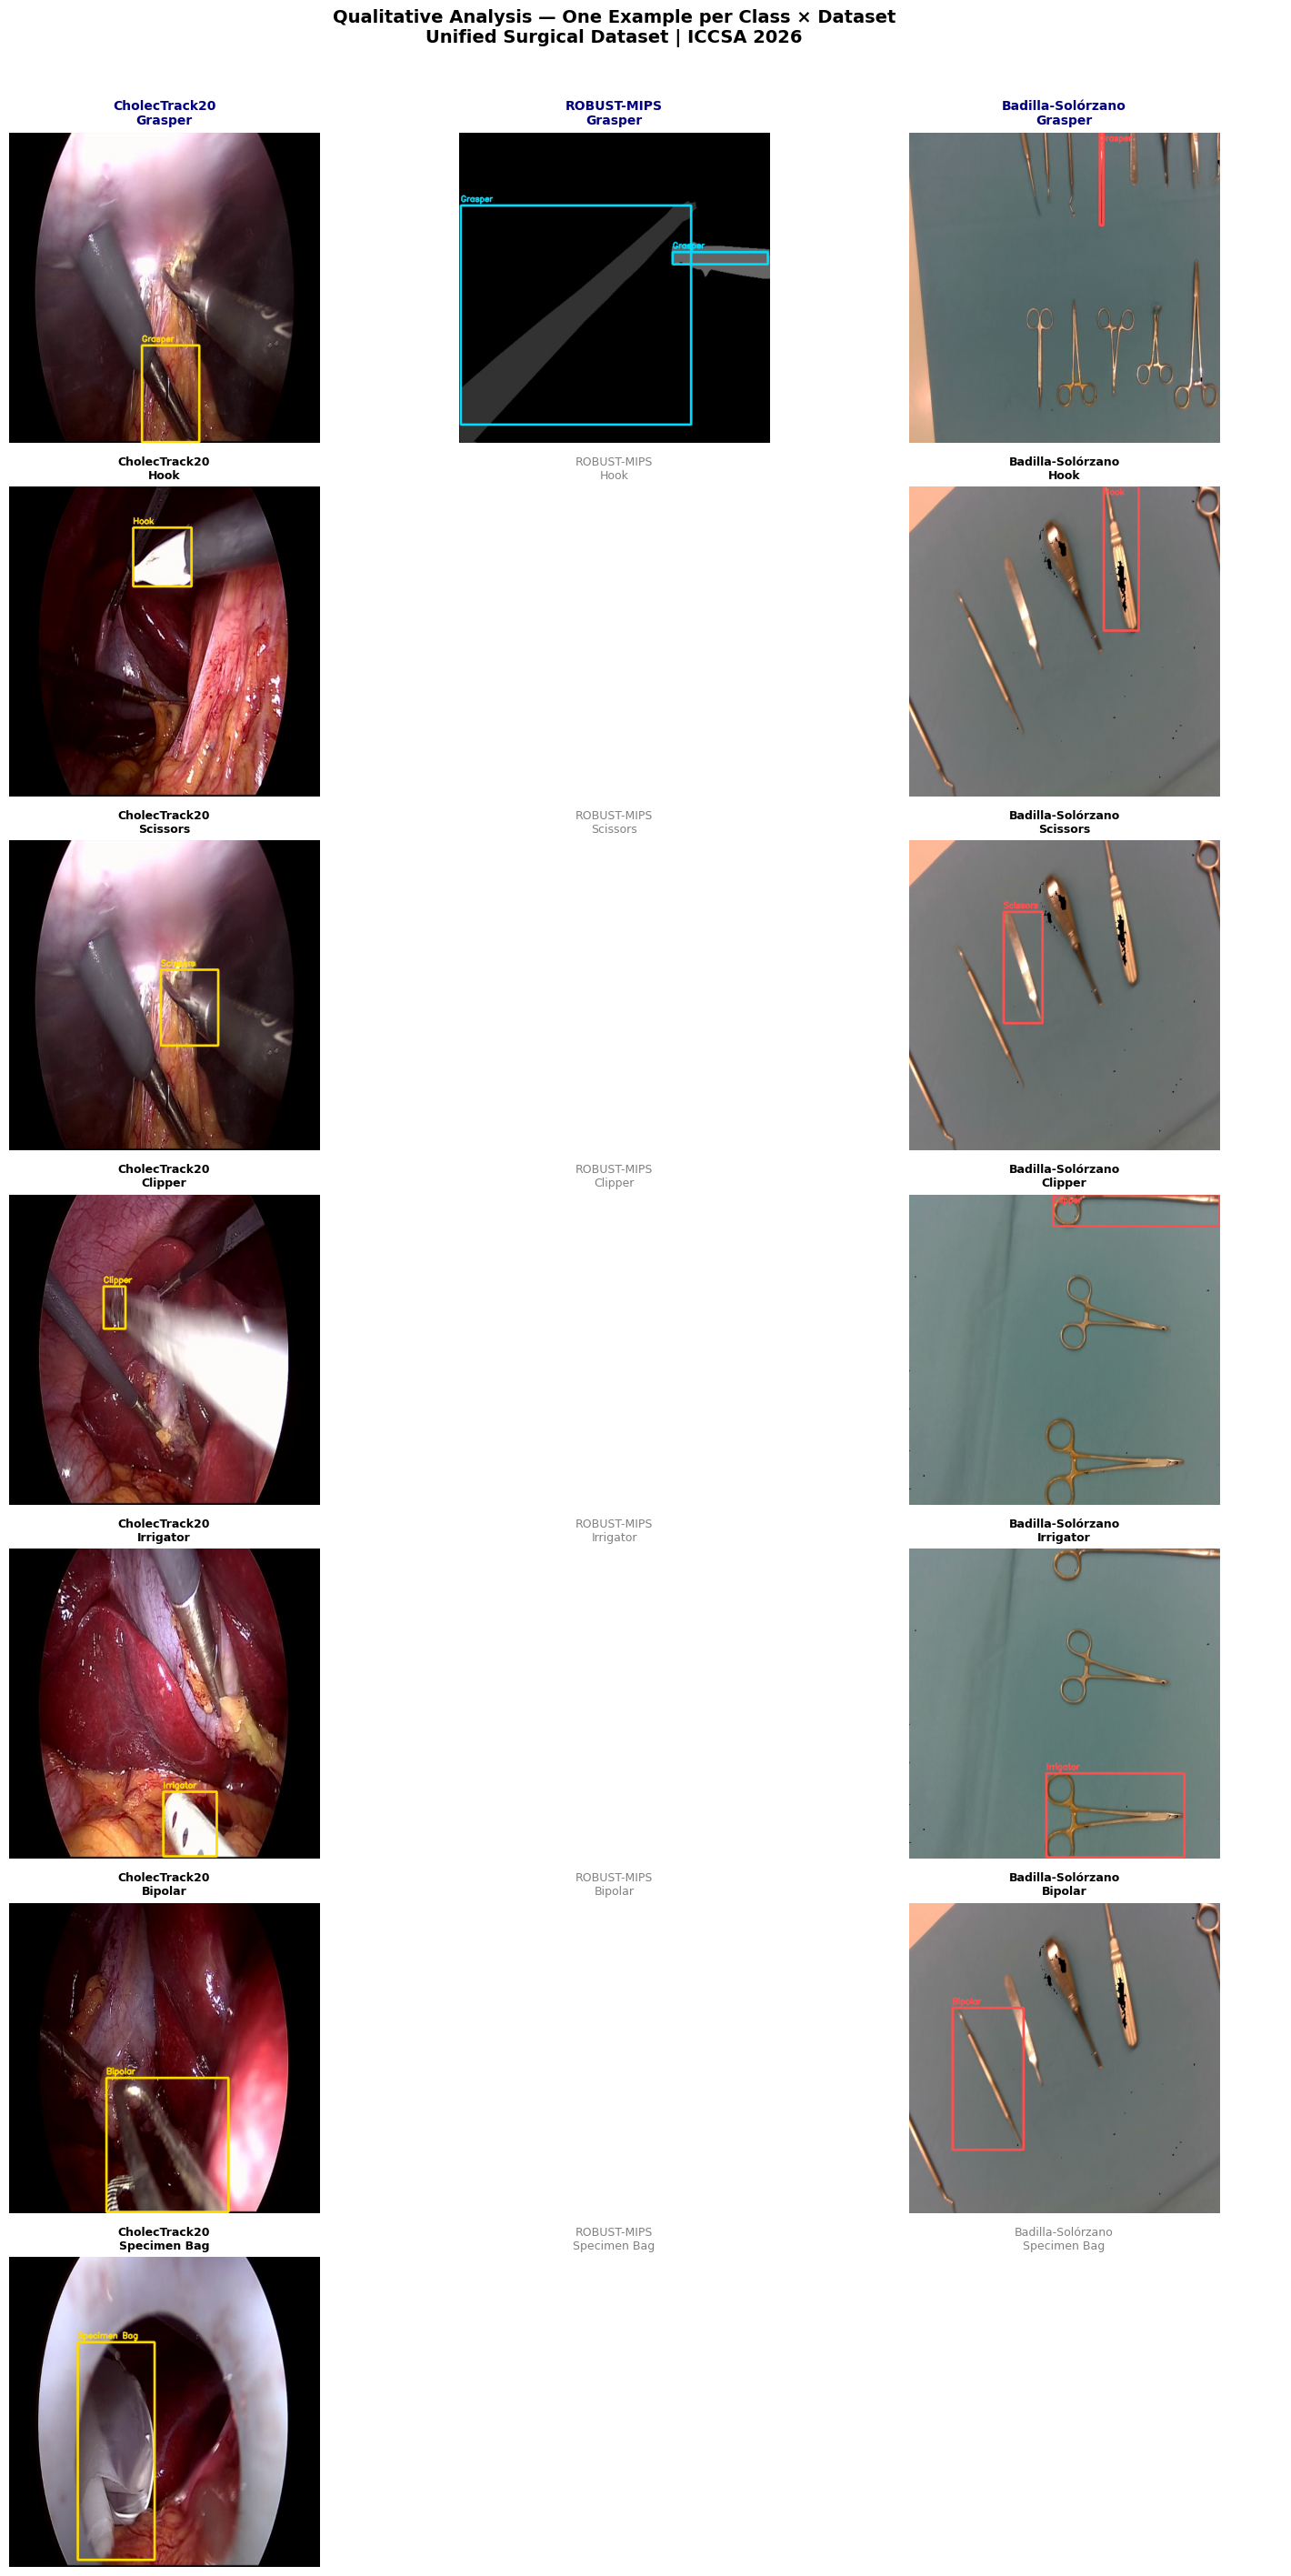


  Data Preparation complete.
  Unified dataset: /content/dataset_unified
  Qualitative PDF: /content/drive/My Drive/project/qualitative_results.pdf


In [18]:
# Saved as PDF to Google Drive/project/qualitative_results.pdf

print("\n" + "=" * 60)
print("  GENERATING QUALITATIVE RESULTS (7 × 3 grid)")
print("=" * 60)

SOURCES = ['cholec', 'robust', 'badilla']
SOURCE_LABELS = {'cholec': 'CholecTrack20', 'robust': 'ROBUST-MIPS', 'badilla': 'Badilla-Solórzano'}
COLORS = {'cholec': (255, 220, 0), 'robust': (0, 220, 255), 'badilla': (255, 80, 80)}

img_dir = os.path.join(OUTPUT_DIR, 'images/train')

# Build index: matrix[class_id][source] = (img_path, lbl_path)
matrix = {i: {src: None for src in SOURCES} for i in range(7)}

for lbl_file in sorted(all_labels):
    src = next((s for s in SOURCES if lbl_file.startswith(s)), None)
    if not src:
        continue
    lbl_path = os.path.join(lbl_dir, lbl_file)
    img_path = os.path.join(img_dir, lbl_file.replace('.txt', '.jpg'))
    if not os.path.exists(img_path):
        continue
    with open(lbl_path, 'r') as f:
        lines = f.readlines()
    for line in lines:
        parts = line.strip().split()
        if not parts:
            continue
        cid = int(parts[0])
        if cid < 7 and matrix[cid][src] is None:
            matrix[cid][src] = (img_path, lbl_path)

def draw_boxes(img_bgr, lbl_path, target_class, color):
    """Draw bounding boxes for a specific class on an image copy."""
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]
    with open(lbl_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if not parts or int(parts[0]) != target_class:
                continue
            _, xc, yc, bw, bh = map(float, parts)
            x1 = max(0, int((xc - bw / 2) * w))
            y1 = max(0, int((yc - bh / 2) * h))
            x2 = min(w, int((xc + bw / 2) * w))
            y2 = min(h, int((yc + bh / 2) * h))
            cv2.rectangle(img_rgb, (x1, y1), (x2, y2), color, 3)
            cv2.putText(img_rgb, CLASS_NAMES[target_class],
                        (x1, max(18, y1 - 8)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)
    return img_rgb

# Build the 7 × 3 figure
fig, axes = plt.subplots(7, 3, figsize=(15, 28))
fig.suptitle("Qualitative Analysis — One Example per Class × Dataset\n"
             "Unified Surgical Dataset | ICCSA 2026",
             fontsize=14, fontweight='bold', y=1.01)

for row, cid in enumerate(range(7)):
    for col, src in enumerate(SOURCES):
        ax = axes[row, col]
        entry = matrix[cid][src]
        color_rgb = COLORS[src]

        if entry:
            img_bgr = cv2.imread(entry[0])
            img_display = draw_boxes(img_bgr, entry[1], cid, color_rgb)
            ax.imshow(img_display)
            ax.set_title(f"{SOURCE_LABELS[src]}\n{CLASS_NAMES[cid]}",
                         fontsize=9, fontweight='bold')
        else:
            ax.set_facecolor('#1a1a1a')
            ax.text(0.5, 0.5, f"{CLASS_NAMES[cid]}\nnot found\nin {SOURCE_LABELS[src]}",
                    ha='center', va='center', color='white',
                    fontsize=8, transform=ax.transAxes)
            ax.set_title(f"{SOURCE_LABELS[src]}\n{CLASS_NAMES[cid]}",
                         fontsize=9, color='gray')

        ax.axis('off')

        # Column headers on first row
        if row == 0:
            ax.set_title(f"{SOURCE_LABELS[src]}\n{CLASS_NAMES[cid]}",
                         fontsize=10, fontweight='bold', color='navy')

plt.tight_layout()

# Save PDF to Google Drive
with pdf_backend.PdfPages(PDF_OUTPUT) as pdf_pages:
    pdf_pages.savefig(fig, bbox_inches='tight')

print(f"\n  PDF saved to: {PDF_OUTPUT}")
plt.show()

print("\n  Data Preparation complete.")
print(f"  Unified dataset: {OUTPUT_DIR}")
print(f"  Qualitative PDF: {PDF_OUTPUT}")